# Прогноз генерації електроенергії на 48 годин

MATH840 Time Series, фінальний проєкт. Анна Ахламова.

**Коротко.** Фінальна модель: Chronos-2, готова навчена модель, із 8192 годинами контексту, усіма погодними колонками
та обмеженою шириною інтервалу. На 30 вікнах без перекриття вона на другому дні прогнозу б'є бенчмарк у 26 вікнах за RMSE
(196 проти 310), у 21 за MAPE (71 проти 155) і в 22 за Winkler (978 проти 2061, тут ще без обмеження).
Ці вікна використовують фактичну погоду, тому оцінки оптимістичні.

Модель Session 1 (динамічна регресія + SNAIVE) на бектесті виглядала добре, але програла бенчмарку на публічних годинах.
Причину цього розриву я вважаю головним уроком проєкту. Код: `01`-`05`, запуск описано в `README.md`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from common import rmse, snaive

plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
MODEL, BENCH = "#2563eb", "#6b7280"
data = pd.read_csv("train.csv", parse_dates=["ds"])
bt = pd.read_csv("backtest_30_windows.csv")
final = pd.read_csv("AKHLAMOVA_project.csv", parse_dates=["ds"])

## 1. Eda

**Рівень.** Дані містять 33 480 годин, з 1 січня 2023 до 27 жовтня 2026. Середнє за роками: 171, 184, 291, 684, а за
останні 60 днів 808. Система сильно зросла, тому стара історія описує менший масштаб.

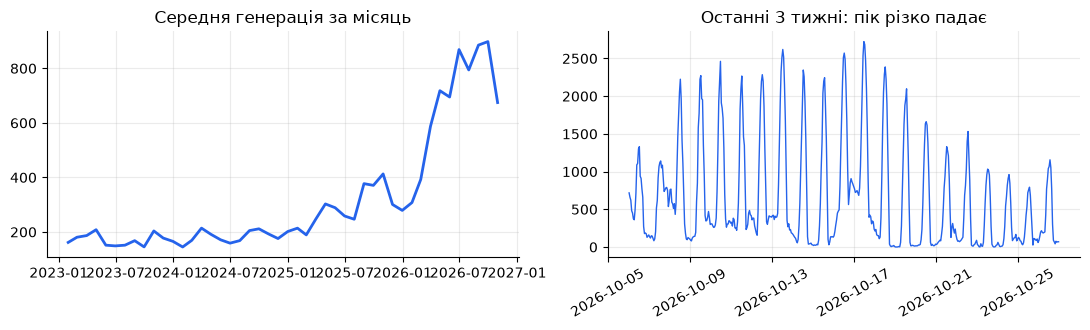

In [2]:
monthly = data.set_index("ds")["y"].resample("ME").mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(monthly.index, monthly.values, color=MODEL, lw=2)
ax[0].set_title("Середня генерація за місяць")
last = data.tail(21 * 24)
ax[1].plot(last["ds"], last["y"], color=MODEL, lw=1)
ax[1].set_title("Останні 3 тижні: пік різко падає")
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**Швидкі зміни рівня.** Денні піки становили 2200-2700 у середині жовтня, а в останні дні лише 800-1150. Отже, рівень може
змінитись за кілька днів, і довгий усереднений профіль може завищувати прогноз.

**Сезонність.** Декомпозиція MSTL за останні 60 днів дає стандартне відхилення 659 для добової частини, 106 для тижневої та
184 для залишку. Головне тут добовий цикл. Автокореляція дорівнює 0.95 на лагу 1, 0.91 на лагу 24 і 0.88 на лагу 48.
Тому SNAIVE сильний бенчмарк, хоча значна частина цього значення походить від самого добового циклу.

**Погода.** За останні 60 днів y корелює з daylight (0.74), wind_speed (0.58), temperature (0.54) і humidity
(-0.59). Отже, погода несе інформацію, якої немає в минулих значеннях ряду. cloud_cover поводиться всупереч назві:
удень середнє y становить 950 при 0 і 2082 при 1. Точної причини такої залежності я не знаю. Спершу я припустила протилежний знак, і таблиця за температурою це спростувала. Також дані нерівномірні:
459 із 720 денних годин за останні 120 днів припадають на тепло й повну хмарність.

**Прогноз погоди.** weather_forecast.csv я використала, бо його масштаб збігається з історією, а погода на цьому ряді
виявилась головним чинником. Період прогнозу холодніший і вологіший за останні 14 днів (9 °C проти 12.5 °C, вологість 96%
проти 88%), тобто модель працює в умовах, які мало траплялись у недавній історії.

**Як це вплинуло на модель.** Потрібна модель, що враховує майбутню погоду і недавній рівень. Звідси спершу динамічна
регресія на 60 днях, а потім Chronos-2 з погодою.

## 2. Перевірка прогнозу

**Вікна.** Кожне вікно: прогноз на 48 годин з більш ранньої точки ряду, без перекриття. Вони починаються о 01:00, як
справжній горизонт, тож години 25-48 відповідають приватним. Тому я оцінюю день 2 окремо. Класичні моделі перевірені на
10 вікнах (останні 20 днів), Chronos на 30 вікнах (останні 60 днів, 4.3% ряду). Я збільшила кількість вікон, бо на малій
кількості висновки нестабільні: SARIMA мала медіанний skill 1.68 на 10 перекритих вікнах і 0.94 на 20. Погода в усіх
вікнах фактична, бо архіву прогнозів немає.

**Класичні моделі 10 вікон.** Дужки: у скількох вікнах модель б'є бенчмарк.

| Модель | RMSE | MAPE | Winkler |
|---|---|---|---|
| ETS(A,Ad,A) | 358 (4) | 371 (1) | 2962 (2) |
| SARIMA(1,0,1)(0,1,1)₂₄ | 306 (4) | 273 (4) | 1464 (5) |
| AutoSARIMA, обмежений пошук | 333 (4) | 259 (5) | 1575 (4) |
| MSTL + ARIMA | 390 (4) | 399 (2) | 4653 (3) |
| Динамічна регресія | 250 (6) | 153 (6) | 1274 (8) |
| Динамічна регресія + SNAIVE | 225 (9) | 224 (7) | 1311 (8) |
| Бенчмарк | 306 | 317 | 2179 |

Моделі без погоди не дали стабільної переваги. Ручна SARIMA і AutoSARIMA близькі, тож автовибір порядку проблеми не вирішив.

**Session 1.** Я здала середнє динамічної регресії та SNAIVE, бо це був найкращий варіант на бектесті. На перших 24 прихованих
годинах він отримав RMSE 245.4, MAPE 99.7%, Winkler 716, а бенчмарк 115.7, 84.3% і 521. Я не перевірила саму гілку з прогнозною
погодою: у weather_forecast.csv регресія давала піки 1887 і 1747, хоча за останні 4 дні історії максимум був 1156.
Точної причини завищення я не встановила, але маю теорію, що регресія усереднила старий високий рівень і не помітила різкого падіння в останні дні, а погодні ознаки ще більше підняли прогноз.

**Chronos-2, 30 вікон.**

| Модель | Частина | RMSE | MAPE | Winkler |
|---|---|---|---|---|
| Chronos+погода | день 2 | 196 (26) | 71 (21) | 978 (22) |
| Chronos без погоди | день 2 | 288 (18) | 136 (16) | 1269 (13) |
| Бенчмарк | день 2 | 310 | 155 | 2061 |
| Chronos+погода | усі 48 годин | 189 (28) | 74 (23) | 887 (26) |
| Бенчмарк | усі 48 годин | 297 | 193 | 2202 |

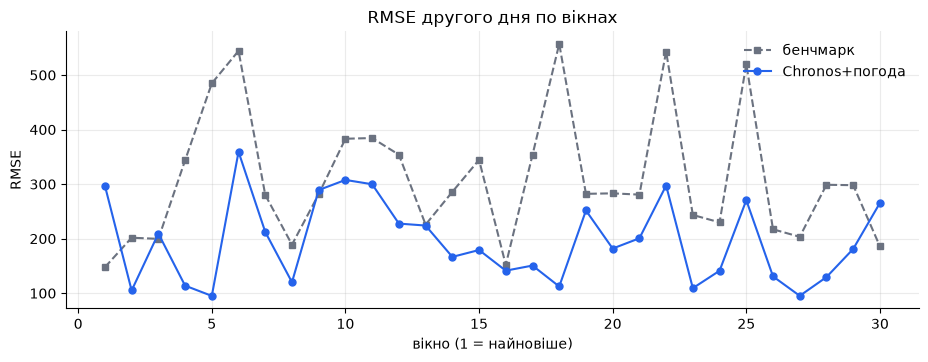

модель краща у 26 вікнах із 30


In [3]:
day2 = bt[bt["step"] > 24]
per_window = day2.groupby("window").apply(lambda g: pd.Series({
    "model": rmse(g["actual"], g["Chronos+weather"]), "benchmark": rmse(g["actual"], g["benchmark"])}), include_groups=False)
plt.plot(per_window.index, per_window["benchmark"], color=BENCH, marker="s", ms=5, ls="--", label="бенчмарк")
plt.plot(per_window.index, per_window["model"], color=MODEL, marker="o", ms=5, label="Chronos+погода")
plt.xlabel("вікно (1 = найновіше)"); plt.ylabel("RMSE"); plt.title("RMSE другого дня по вікнах")
plt.legend(frameon=False); plt.show()
print("модель краща у", int((per_window["model"] < per_window["benchmark"]).sum()), "вікнах із", len(per_window))

Перевага стабільна, але не абсолютна: бенчмарк усе ще виграє частину вікон. Без погоди RMSE другого дня 288, тому реальний
результат з прогнозною погодою, найімовірніше, буде між 196 і 288, хоча один день може вийти за ці межі.

**Налаштування Chronos.** Спершу контекст 2048 годин я взяла без обґрунтування, тому порівняла 9 конфігурацій на 10 вікнах.
Модель приймає максимум 8192 години. На 10 вікнах це дало кращі RMSE і MAPE (211 і 110 проти 236 і 132), але гірший Winkler
(1102 проти 1052). інтервал я обмежую окремо, тому вибрала 8192.

**Публічний результат.** Попередня версія (2048 годин, без обмеження меж) на перших 24 годинах отримала RMSE 51.6, MAPE 31.3%,
Winkler 956 при покритті 100%. Це один день, тому ці числа не оцінюють якість моделі, і я не підбирала модель під них.
Поточний файл відрізняється від тієї версії, тому його публічного результату в цьому звіті немає.

## 3. Обгрунтування CI

**Як він побудований.** Межі йдуть від квантилів 0.025 і 0.975 самої моделі. Перевірка на днях 2 показала, що вони занадто
широкі: покриття 0.98. Плаский conformal-інтервал з лаб дав Winkler 1013 проти 978, отже форма від Chronos корисна.

**Обмеження ширини.** Для реального прогнозу ширина другого дня була 1480, тоді як найширше вікно бектесту мало 1139, а зв'язок
ширини з помилкою слабкий (кореляція 0.29). Тому я обрізаю половину ширини до CAP × типової половини ширини для цього кроку.
Сам прогноз не змінюється. Таблиця нижче: 20 вікон, типову ширину для кожного беру лише зі старіших вікон.

| CAP | Winkler, середнє | Winkler, медіана | Покриття | Ширина |
|---|---|---|---|---|
| без обмеження | 1031 | 1049 | 0.98 | 985 |
| 1.5 | 1013 | 1019 | 0.98 | 967 |
| 1.2 | 980 | 945 | 0.97 | 908 |
| **1.0** | **965** | 843 | 0.97 | 815 |
| 0.9 | 965 | 774 | 0.95 | 746 |
| 0.8 | 1007 | 696 | 0.92 | 670 |
| 0.7 | 1112 | 645 | 0.88 | 592 |
| 0.5 | 1609 | 1091 | 0.74 | 429 |

Я вибрала CAP = 1.0. Значення 0.9 дає той самий середній Winkler, але покриття вже на межі, а реальні похибки з прогнозом
погоди мають бути більшими. Вузький інтервал, як у лідерів публічної таблиці, тут не підходить: на днях 2 похибка перевищує
419 у 5% годин, тому потрібна ширина приблизно 840, а не 500. У фінальному файлі ширина 659 у перший день і 789 у другий.

**Важливе застереження.** Рішення перевіряти обмеження з'явилось після публічного Winkler 956, який дорівнював ширині файлу.
Значення CAP вибрано за вікнами, а не за лідербордом, але на прогнозній погоді його не перевірено. Якщо погода сильно
помилиться, вужчий інтервал програє ширшому.

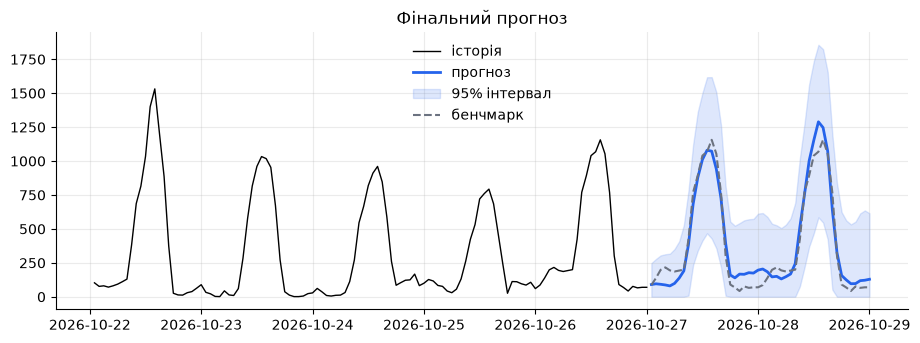

In [4]:
history = data.tail(5 * 24)
plt.plot(history["ds"], history["y"], color="black", lw=1, label="історія")
plt.plot(final["ds"], final["forecast"], color=MODEL, lw=2, label="прогноз")
plt.fill_between(final["ds"], final["lower_95"], final["upper_95"], color=MODEL, alpha=0.15, label="95% інтервал")
plt.plot(final["ds"], snaive(data["y"].to_numpy(float))[0], color=BENCH, ls="--", label="бенчмарк")
plt.title("Фінальний прогноз"); plt.legend(frameon=False); plt.show()

## 4. Що не спрацювало?

**Залишки.** Це помилки Chronos+погода на 30 вікнах.

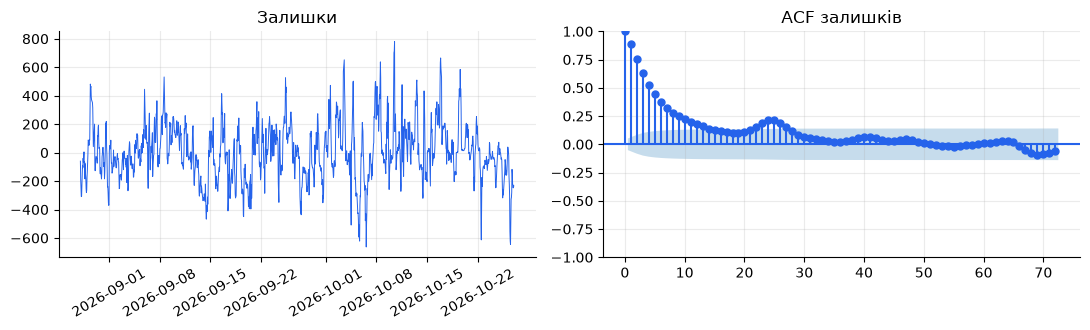

середнє 2.4; лаг 1: 0.89, лаг 24: 0.22, лаг 48: 0.04


In [5]:
ordered = bt.sort_values(["window", "step"], ascending=[False, True])
residual = (ordered["actual"] - ordered["Chronos+weather"]).reset_index(drop=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(pd.to_datetime(ordered["ds"]), residual, color=MODEL, lw=0.7)
ax[0].set_title("Залишки"); ax[0].tick_params(axis="x", rotation=30)
plot_acf(residual, lags=72, ax=ax[1], title="ACF залишків", color=MODEL, vlines_kwargs={"colors": MODEL})
plt.tight_layout(); plt.show()
print(f"середнє {residual.mean():.1f}; лаг 1: {residual.autocorr(1):.2f}, лаг 24: {residual.autocorr(24):.2f}, лаг 48: {residual.autocorr(48):.2f}")

Середній залишок близько 2, тому суттєвого зміщення немає. Але це не білий шум: автокореляція 0.89 на лагу 1, тест Льюнга-Бокса
відхиляє незалежність. Помилка тримається годинами, тобто модель може помилитись на рівень цілого дня. Зв'язок слабшає до 0.22
на лагу 24 і майже зникає на лагу 48. Вікна тут склеєні одне за одним, тому це радше опис, ніж строгий тест.

**Що я спробувала й відкинула.**

| Підхід | Результат | Рішення |
|---|---|---|
| ETS, SARIMA, AutoSARIMA, MSTL | Не бачать погоди, стабільної переваги немає | Лише для порівняння |
| Ансамбль ETS+SARIMA+MSTL | Медіанний skill 0.99 на 20 перекритих вікнах | Відкинуто: моделі мають спільну слабкість |
| Динамічна регресія + SNAIVE | Добрий бектест, RMSE 245 на публічних годинах | Файл Session 1, далі відкинуто |
| Коротші вікна і простіша хмарність у регресії | Пік другого дня 1750-2150 в усіх 12 варіантах | Відкинуто |
| Chronos + SNAIVE, 50/50 | Більше перемог (28 за RMSE), гірші середні: RMSE 228, MAPE 108 | Відкинуто |
| Chronos + AutoSARIMA | Кожна вага погіршила RMSE і MAPE (перевірено на 2048 годинах) | Відкинуто |
| Лог-перетворення `y` | MAPE 95, але RMSE 264 і Winkler 1231 | Відкинуто |
| Лог-прогноз лише вночі | Виграш MAPE тримається на кількох екстремальних вікнах | Відкинуто |
| Менше погодних колонок | Кращий Winkler, гірший RMSE, різниця мала | Лишила всі колонки |
| Дотренування Chronos | Не вмістилось у пам'ять на CPU, навіть із меншим батчем | Не виконано |
| Conformal-інтервал | Winkler 1013 проти 978 | Відкинуто |
| TimeGPT | Не запускала: платний зовнішній сервіс із ключем | Не перевірено |

**Обмеження висновків.**

- Усі вікна мають фактичну погоду, тому оцінки оптимістичні. На цьому зламалась модель Session 1.
- Вікна покривають лише кінець серпня - жовтень, тому висновки стосуються цього сезону.
- Кілька рішень прийняті на 10-30 вікнах після багатьох порівнянь, тому невеликі різниці можуть бути випадковими.
- Chronos навчали на чужих даних. Я не можу перевірити, чи не було серед них цього ряду, тому бектест може бути завищеним.

**Що я зробила б інакше.** Перед здачею я б перевірила модель на погоді зі штучно доданими похибками, бо в бектесті стояла фактична погода. Також порівняла б прогноз із недавніми піками: пік 1887 при недавньому максимумі 1156 був помітним сигналом. І одразу дивилась би на результат бенчмарку на найновіших вікнах, а не лише на середнє.

Використання LLM описано в README.md.